# Introduction to Simple Linear Regression

In this basic example, we will delve into the creation of a straightforward linear regression model, which represents the classic equation of y = mx + b. We will meticulously walk through each step to illustrate the types of questions a simple linear regression model can address. Please note that this example is intentionally simplified and does not reflect the more sophisticated approaches we will explore later. Its purpose is to provide you with an introductory understanding of linear regression, reminiscent of the work of [Francis Galton](https://en.wikipedia.org/wiki/Francis_Galton).


## Imports

In [1]:
#Import necessary libraries that I can use
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



## Overview of Sample Data

The dataset provided is sourced from ISLR (Introduction to Statistical Learning with Applications in R). It presents sales figures in thousands of units for a specific product, which are influenced by advertising expenditures in thousands of dollars across various media channels, including TV, radio, and newspapers.


In [2]:


# Load the data from the "Advertising.csv" file into a DataFrame
df = pd.read_csv(r"C:\Users\fafzali\Downloads\Machine learning\Code\Linear Regression\Advertising.csv")

# Explanation:
# - We import the 'pandas' library using the 'import' statement.
# - We use the 'read_csv' function from pandas to read data from a CSV file named "Advertising.csv."
# - The data is loaded into a DataFrame named 'df,' which is a tabular data structure in pandas.
# - Now, you can perform various data analysis and manipulation tasks on the 'df' DataFrame.

# Display the first few rows of the DataFrame to inspect the data
df.head()


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
df.tail(10)

,TV,radio,newspaper,sales
190,39.5,41.1,5.8,10.8
191,75.5,10.8,6.0,9.9
192,17.2,4.1,31.6,5.9
193,166.8,42.0,3.6,19.6
194,149.7,35.6,6.0,17.3
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


**Is there a relationship between *total* advertising spend and *sales*?**

In [4]:
# Calculate the total advertising spend
df['total_spend'] = df['TV'] + df['radio'] + df['newspaper']

# Explanation:
# - We create a new column 'total_spend' in the DataFrame 'df' to represent the total advertising expenditure.
# - To calculate this total, we add the values from the 'TV,' 'radio,' and 'newspaper' columns.
# - This operation aggregates the advertising budgets from different media channels and stores the result in the 'total_spend' column.

# Display the updated DataFrame with the 'total_spend' column
df.head()


,TV,radio,newspaper,sales,total_spend
0,230.1,37.8,69.2,22.1,337.1
1,44.5,39.3,45.1,10.4,128.9
2,17.2,45.9,69.3,9.3,132.4
3,151.5,41.3,58.5,18.5,251.3
4,180.8,10.8,58.4,12.9,250.0


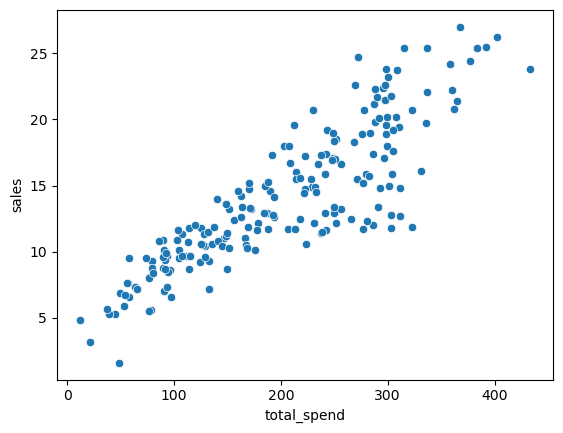

In [5]:
# Create a scatterplot to visualize the relationship between advertising spend and sales
sns.scatterplot(x='total_spend', y='sales', data=df)

# Explanation:
# - We use the Seaborn library, typically imported as 'sns,' to create a scatterplot.
# - The 'x' parameter is set to 'total_spend,' which represents the total advertising expenditure on the x-axis.
# - The 'y' parameter is set to 'sales,' representing the sales figures on the y-axis.
# - The 'data' parameter is set to 'df,' which specifies that the data for the plot is sourced from the 'df' DataFrame.
# - This scatterplot helps us visualize the relationship between total advertising spend and sales. It allows us to observe if there's any correlation or pattern between these two variables.

# Display the scatterplot
plt.show()


## Least Squares Line

In the context of linear regression, the "Least Squares Line" is a fundamental concept. It represents the line that minimizes the sum of the squared differences between the observed values (in our case, 'sales') and the predicted values (which are calculated using a linear equation). This line is often used to model relationships between variables, such as advertising expenditure and sales.

The formula for the Least Squares Line involves the calculation of the slope ('m') and the intercept ('b') of the line. For a more detailed understanding of these formulas, you can refer to the [Wikipedia page on Linear Regression](https://en.wikipedia.org/wiki/Linear_regression) or consult the reading material provided in ISLR (Introduction to Statistical Learning with Applications in R).

Understanding the Least Squares Line is crucial in linear regression, as it helps us make predictions based on our data and assess the strength and nature of relationships between variables.

Feel free to explore the linked resources for a deeper dive into the mathematical foundations of linear regression.


## Exploring the Insights of a Best-Fit Line

Suppose you have a total budget of $200. The question that naturally arises is, what can you expect in terms of sales with this budget? Although we've simplified the analysis by aggregating all the features into "total spend," we will delve into individual features later. For now, our primary focus is on understanding the types of inquiries that a linear regression line can help address.

Let's consider a practical scenario: If our upcoming advertising campaign is allocated a total budget of $200, how many units can we anticipate selling as a direct result of this expenditure?


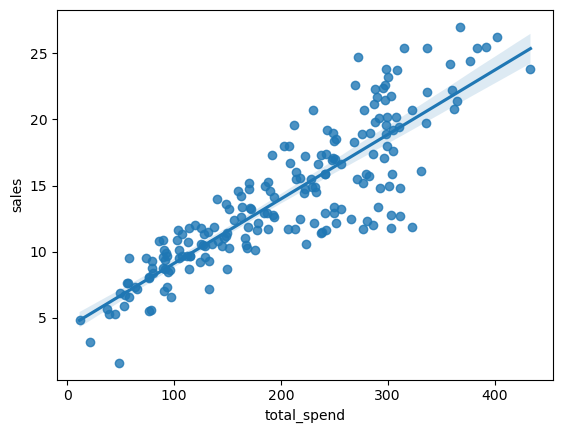

In [7]:


# Create a regression plot to visualize the best-fit line
sns.regplot(x='total_spend', y='sales', data=df)

# Explanation:
# - We start by importing the required libraries, 'seaborn' and 'matplotlib.pyplot.'
# - Next, we use 'sns.regplot' to create a regression plot:
#   - 'x='total_spend'' specifies that the 'total_spend' column from the DataFrame 'df' should be on the x-axis.
#   - 'y='sales'' indicates that the 'sales' column from 'df' should be plotted on the y-axis.
#   - 'data=df' specifies that the data for this plot comes from the 'df' DataFrame.
# - The result is a scatterplot with a best-fit line, which is calculated using regression analysis.
# - This best-fit line represents the relationship between advertising expenditure ('total_spend') and sales ('sales').
# - The visualization helps us understand how changes in advertising spending may impact sales and provides insights into the linear relationship between these variables.

# Display the regression plot
plt.show()


Let's go ahead and start solving: $$y=mx+b$$

## Solving for Beta Coefficients

In linear regression, we aim to determine the coefficients, often denoted as $\beta_0$ (intercept) and $\beta_1$ (slope), in a generalized form:

$$ \hat{y} = \beta_0 + \beta_1X $$

Here, we use capital letters to denote matrices of values. We have a known matrix of labels (sales numbers), represented as Y, and a known matrix of total expenditures (total_spend), represented as X. Our objective is to solve for the *beta* coefficients, which become increasingly important as we expand our analysis to include more than just a single feature. These coefficients help us understand the predictive power of various features in our model. The symbol $\hat{y}$ signifies a prediction or estimation, while 'y' represents the true label or known value.

To calculate these coefficients, we can utilize NumPy, a powerful Python library for numerical computations. However, if you're inclined, you can also solve this problem manually, as demonstrated in this [hand-calculation example](https://towardsdatascience.com/linear-regression-by-hand-ee7fe5a751bf).

Understanding and computing these coefficients is a fundamental step in linear regression, as they define the relationship between the independent variable(s) and the dependent variable, allowing us to make predictions based on our data.


In [8]:
X = df['total_spend']
y = df['sales']

In [6]:
help(np.polyfit)

Help on function polyfit in module numpy:

polyfit(x, y, deg, rcond=None, full=False, w=None, cov=False)
    Least squares polynomial fit.
    
    .. note::
       This forms part of the old polynomial API. Since version 1.4, the
       new polynomial API defined in `numpy.polynomial` is preferred.
       A summary of the differences can be found in the
       :doc:`transition guide </reference/routines.polynomials>`.
    
    Fit a polynomial ``p(x) = p[0] * x**deg + ... + p[deg]`` of degree `deg`
    to points `(x, y)`. Returns a vector of coefficients `p` that minimises
    the squared error in the order `deg`, `deg-1`, ... `0`.
    
    The `Polynomial.fit <numpy.polynomial.polynomial.Polynomial.fit>` class
    method is recommended for new code as it is more stable numerically. See
    the documentation of the method for more information.
    
    Parameters
    ----------
    x : array_like, shape (M,)
        x-coordinates of the M sample points ``(x[i], y[i])``.
    y : array_

In [10]:


# Perform linear regression using numpy.polyfit
coefficients = np.polyfit(X, y, 1)

# Explanation:
# - We start by importing the 'numpy' library as 'np.'
# - The code utilizes the 'np.polyfit' function to perform linear regression:
#   - 'X' represents the independent variable (total spend), and 'y' represents the dependent variable (sales).
#   - The '1' as the second argument indicates that we want to fit a first-degree polynomial, which is a linear regression model.
# - The 'np.polyfit' function returns a list of coefficients, with the highest-order coefficient first.
#   - In this case, it returns the slope (beta_1) as the first coefficient and the intercept (beta_0) as the second coefficient.

# The 'coefficients' variable now holds the values [beta_1, beta_0], which represent the slope and intercept of the best-fit line.

# You can use these coefficients to create the linear regression model and make predictions.

# Display the coefficients
coefficients


array([0.04868788, 4.24302822])

In [11]:
# Potential Future Spend Budgets
potential_spend = np.linspace(0,500,100)

In [12]:
#y=mx+b 
predicted_sales =  0.04868788*potential_spend + 4.24302822

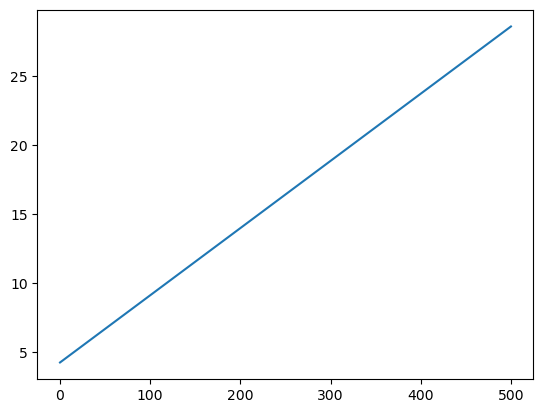

In [13]:
plt.plot(potential_spend,predicted_sales)

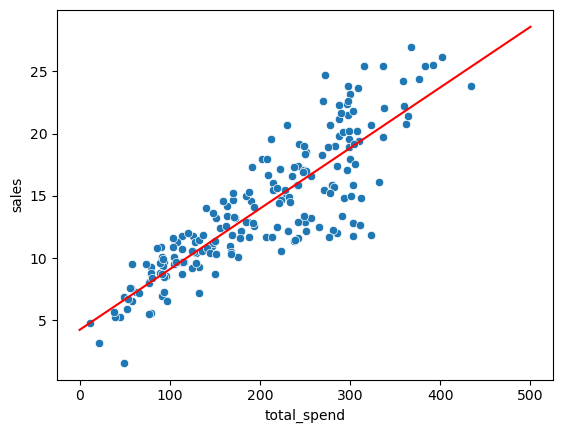

In [15]:


# Create a scatterplot to visualize the relationship between advertising spend and sales
sns.scatterplot(x='total_spend', y='sales', data=df)

# Explanation:
# - We import the 'seaborn' library as 'sns' for creating the scatterplot and 'matplotlib.pyplot' as 'plt' for additional plotting.
# - The first line ('sns.scatterplot') generates a scatterplot to visualize the relationship between 'total_spend' (x-axis) and 'sales' (y-axis) using data from the 'df' DataFrame.
#   - This scatterplot displays the observed data points.
# - The next line ('plt.plot') adds a red line to the plot to represent the predicted sales based on 'potential_spend.'
#   - 'potential_spend' should be a sequence of values corresponding to different advertising budgets you want to predict sales for.
#   - 'predicted_sales' should be a sequence of values representing the sales predictions corresponding to 'potential_spend.'
#   - The 'color' parameter is set to 'red' to make the line stand out.

# This combined visualization allows you to compare the observed data points to the predictions represented by the red line, providing insights into how well your model fits the data.

# Display the scatterplot with the red line

plt.plot(potential_spend,predicted_sales,color='red')
plt.show()


In [7]:
#tv=100, newspaper=50, radio=10
spend = 160
predicted_sales =  0.04868788*spend + 4.24302822

In [8]:
predicted_sales

12.033089020000002

# Further considerations...which we will explore in much more depth!

## Overfitting, Underfitting, and Measuring Performance

Notice we fit to order=1 , essentially a straight line, we can begin to explore higher orders, but does higher order mean an overall better fit? Is it possible to fit too much? Too little? How would we know and how do we even define a good fit?

In [16]:

# Perform polynomial regression of degree 3 using np.polyfit
coefficients = np.polyfit(X, y, 3)

# Explanation:
# - We import the 'numpy' library as 'np.'
# - The code utilizes the 'np.polyfit' function to perform polynomial regression of degree 3:
#   - 'X' represents the independent variable (total spend), and 'y' represents the dependent variable (sales).
#   - The '3' as the second argument indicates that we want to fit a third-degree polynomial.
# - The 'np.polyfit' function returns a list of coefficients, with the highest-order coefficient first.
#   - In this case, it returns coefficients for the terms corresponding to X^3, X^2, X, and the intercept.

# The 'coefficients' variable now holds the values [beta_3, beta_2, beta_1, beta_0], which represent the coefficients of the polynomial regression model.

# You can use these coefficients to create and evaluate a polynomial regression model of degree 3.

# Display the coefficients
coefficients


array([ 3.07615033e-07, -1.89392449e-04,  8.20886302e-02,  2.70495053e+00])

In [17]:
# Potential Future Spend Budgets
potential_spend = np.linspace(0,500,100)

In [18]:
predicted_sales =   3.07615033e-07*potential_spend**3 + -1.89392449e-04*potential_spend**2 + 8.20886302e-02*potential_spend**1 + 2.70495053e+00

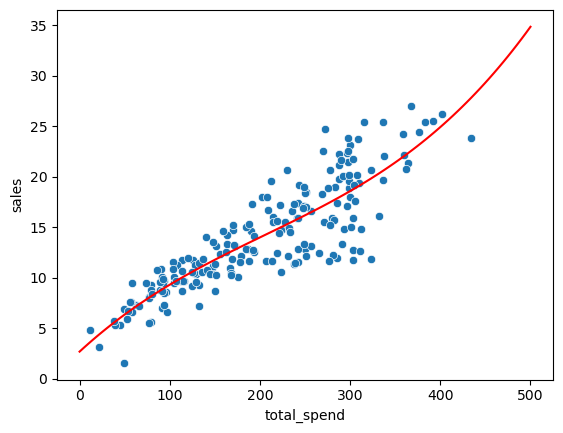

In [19]:
sns.scatterplot(x='total_spend',y='sales',data=df)
plt.plot(potential_spend,predicted_sales,color='red')

**Is this better than our straight line fit? What are good ways of measuring this?**

## Multiple Features

The real data had 3 features, not everything in total spend, this would allow us to repeat the process and maybe get a more accurate result?

In [20]:
X = df[['TV','radio','newspaper']]
y = df['sales']

In [21]:
# Note here we're passing in 3 which matches up with 3 unique features, so we're not polynomial yet
np.polyfit(X,y,1)

TypeError: expected 1D vector for x

**Uh oh! Polyfit only works with a 1D X array! We'll need to move on to a more powerful library...**

-------
--------